# Pipeline completo con la cabeza de clasificación CLIP: solo cambia `P[r]`

**Proyecto IA2 · conteo de calorías por foto**

Este notebook replica el pipeline que discutimos (B1 → regiones · DPT → profundidad · cabeza de nutrición con plano local, masa física y calorías por Atwater) y cambia **una sola cosa**: **cómo se obtiene `P[r]`**, el vector de clase de cada región.

```
ANTES                                            AHORA
foto ─► B1 ─► mapa de clase por píxel            foto ─► B1 ─► mapa de clase por píxel            (igual)
              └► regiones (componentes)                        └► regiones (componentes)           (igual)
                    └► P[r] = promedio de las                        └► recorte masked + bbox
                       probabilidades de B1 (top-6)                      └► CLIP-L/14 ─► cabeza lineal ─► P[r]
foto ─► DPT ─► mapa de profundidad               foto ─► DPT ─► mapa de profundidad               (igual)
```

### Qué cambia y qué no

| Entrada de la cabeza de nutrición | ¿Cambia? | Por qué |
|---|---|---|
| `P` (104 por región) | **Sí** | Ahora sale de la cabeza de clasificación y no del promedio de probabilidades de B1 |
| `area_frac`, `h_mean`, `h_std`, `h_p90`, `vol` (`G`) | No | Salen de las máscaras de B1 y la profundidad; la cabeza de clasificación no toca las máscaras |
| `plane_cm`, `food_frac`, `n_regions`, `h_mean_all`, `vol_total` (`GL`) | No | Igual que `G` |
| `M`, `A`, `V` | No | Derivadas de `G` |
| Arquitectura, pérdida y entrenamiento de la cabeza de nutrición | No | Código idéntico al de la v2. Solo se **reentrena**, porque `cls_emb` y la tabla de densidades se aprendieron con la `P` de B1 |

Para demostrar que de verdad no se tocó nada más, el notebook calcula las dos versiones (`P` de B1 y `P` de la cabeza) **a partir de las mismas regiones**, comprueba que `G`, `GL` y `M` son los mismos arrays y, si existe el caché de la v2, que coinciden con él.

### Qué necesitas tener a mano
1. **B1** en `SEG_DIR`: el mismo de la v2. Si cambias de B1, las regiones cambian y los cachés de segmentación hay que borrarlos.
2. **El DPT** (`depth_model_final.pt` y `depth_inference.py`), igual que en la v2.
3. **La cabeza de clasificación entrenada**: `cabeza_clip_lineal.pt`, que escribe el notebook de segmentación + clasificación cuando `EXPORT = True`. Este notebook **no** la entrena, solo la usa.
4. Nutrition5k con `metadata/` y `realsense_overhead/`, y GPU con CUDA.

### Qué se dejó fuera a propósito
Todo lo que no es el pipeline: la profundidad real (`gt`), el plano de la mesa, las variantes de masa y calorías libres y la variante sin profundidad. Solo quedan la v2 completa, con la profundidad predicha por el DPT, y la comparación entre las dos formas de obtener `P`.

### Índice
1. Configuración y datos · 2. Splits · 3. Modelos congelados (B1, DPT, CLIP + cabeza) · 4. Etapa 1: salidas crudas · 5. Etapa 2: regiones, features y **`P` con la cabeza** · 6. Diagnóstico · 7. La cabeza de nutrición (sin cambios) · 8. Experimento: `P` de B1 vs `P` de la cabeza · 9. Modelo final e inferencia · 10. Límites

## 1. Configuración

Todo lo ajustable está en la celda siguiente. La sección **🆕** es lo nuevo respecto a la v2; lo demás es idéntico.

- `CACHE_DIR` apunta al **mismo caché de la v2** para reutilizar `raw_seg.npz` y `raw_depth_model.npz` (se validan contra la lista de platos; si no coinciden, se recalculan). Lo nuevo se guarda en archivos con otro nombre (`clip_feats_model_local.npz`) y no pisa nada.
- `P_MODE` decide cómo entra la cabeza a `P`:
  - `"head"`: `P[r]` es la distribución de la cabeza (103 clases de alimento) y el componente del fondo vale 0.
  - `"tau"`: si la cabeza tiene confianza ≥ `TAU`, `P[r]` es la de la cabeza; si no, conserva la de B1. Es el análogo suave de la regla `prob ≥ 0.3, si no B1` del notebook de clasificación.

In [15]:
from pathlib import Path
import csv, json, time, math, random, warnings, hashlib
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from scipy import ndimage as ndi
import matplotlib.pyplot as plt
from PIL import Image

# ============ 🔧 RUTAS ============
N5K_ROOT     = Path(r"C:\nutrition5k")                        # contiene metadata/ y realsense_overhead/
SEG_DIR      = Path(r"C:\foodseg_segformer\mit-b1")           # SegFormer-B1 (formato Hugging Face): el MISMO de la v2
CACHE_DIR    = Path("head_cache_v2"); CACHE_DIR.mkdir(exist_ok=True)   # mismo caché de la v2 (reutiliza raw_seg y raw_depth_model)

# ============ 🔧 PROFUNDIDAD (solo la predicha por el DPT: es la que existirá en la app) ============
DEPTH_CKPT      = Path(r"C:\nutrition5k\depth_finetune\depth_model_final.pt")
DEPTH_INFER_DIR = DEPTH_CKPT.parent                           # carpeta con depth_inference.py

# ============ GEOMETRÍA / REGIONES (idéntico a la v2) ============
S, SEG_INPUT = 128, 512
SEG_MEAN, SEG_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
MIN_PX, R_MAX, BG_ID = 24, 16, 0
K_TOP = 6
RING_IN, RING_OUT = 2, 8
N_FOLDS = 5

# ============ 🆕 CABEZA DE CLASIFICACIÓN ============
CLIP_HEAD_PT = Path(r"C:\Users\mjcor\OneDrive\Desktop\Proyecto IA\export_final\cabeza_clip_lineal.pt")    # la escribe el notebook de segmentación+clasificación (EXPORT = True)
CLIP_NAME    = "openai/clip-vit-large-patch14"
K_FOOD       = 103        # clases de alimento de FoodSeg103 (el id 0 es el fondo)
CLIP_PAD     = 10         # margen (px) alrededor del recorte: el mismo PAD del notebook de clasificación
CLIP_FLUSH   = 256        # regiones que se acumulan antes de pasarlas por CLIP (mejor uso de la GPU)
P_MODE       = "head"     # "head" (siempre la cabeza) | "tau" (cabeza si confía, si no B1)
TAU          = 0.3        # umbral de confianza, solo se usa con P_MODE = "tau"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42
TARGETS = ["mass", "kcal", "fat", "carb", "protein"]
UNITS   = ["g", "kcal", "g", "g", "g"]

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(SEED)
print("device:", DEVICE, "| P_MODE:", P_MODE, "| cabeza:", CLIP_HEAD_PT)

device: cuda | P_MODE: head | cabeza: C:\Users\mjcor\OneDrive\Desktop\Proyecto IA\export_final\cabeza_clip_lineal.pt


### Nombres de las clases
Los 103 nombres de FoodSeg103 en el orden estándar del dataset (id 1 = `candy`, …, id 103 = `other ingredients`; el id 0 es el fondo). Es la **misma lista** del notebook de clasificación. Aquí sirve para dos cosas: comprobar que la cabeza y B1 usan el mismo orden de ids, y poner nombres legibles en las tablas.

In [2]:
CLASS_NAMES = ["candy","egg tart","french fries","chocolate","biscuit","popcorn","pudding","ice cream","cheese butter","cake",
 "wine","milkshake","coffee","juice","milk","tea","almond","red beans","cashew","dried cranberries","soy","walnut","peanut","egg",
 "apple","date","apricot","avocado","banana","strawberry","cherry","blueberry","raspberry","mango","olives","peach","lemon","pear",
 "fig","pineapple","grape","kiwi","melon","orange","watermelon","steak","pork","chicken duck","sausage","fried meat","lamb","sauce",
 "crab","fish","shellfish","shrimp","soup","bread","corn","hamburg","pizza","hanamaki baozi","wonton dumplings","pasta","noodles",
 "rice","pie","tofu","eggplant","potato","garlic","cauliflower","tomato","kelp","seaweed","spring onion","rape","ginger","okra",
 "lettuce","pumpkin","cucumber","white radish","carrot","asparagus","bamboo shoots","broccoli","celery stick","cilantro mint",
 "snow peas","cabbage","bean sprouts","onion","pepper","green beans","French beans","king oyster mushroom","shiitake",
 "enoki mushroom","oyster mushroom","white button mushroom","salad","other ingredients"]
assert len(CLASS_NAMES) == K_FOOD
ID2NAME = {0: "background", **{i + 1: n for i, n in enumerate(CLASS_NAMES)}}

## 2. Datos: totales por plato, platos ilegibles y chequeo de Atwater

Igual que en la v2: se leen los 6 primeros campos del CSV, los platos se ordenan por `dish_id` y se filtran **una sola vez** los que tengan `rgb.png` o `depth_raw.png` ilegibles. Aunque aquí no se use la profundidad real, se mantiene el filtro de `depth_raw.png` para que el conjunto de platos (y los pliegues) sea **exactamente el de la v2** y los resultados sean comparables.

In [3]:
img_root = N5K_ROOT / "realsense_overhead"

def load_metadata(meta_dir):
    rows = []
    for fn in ["dish_metadata_cafe1.csv", "dish_metadata_cafe2.csv"]:
        p = meta_dir / fn
        if not p.exists():
            warnings.warn(f"no existe {p}"); continue
        with open(p, newline="", encoding="utf-8") as f:
            for r in csv.reader(f):
                if len(r) < 6: continue
                try:
                    dish, kcal, mass, fat, carb, prot = r[0], *[float(x) for x in r[1:6]]
                except ValueError:
                    continue
                rows.append([dish, mass, kcal, fat, carb, prot])
    return pd.DataFrame(rows, columns=["dish_id"] + TARGETS)

def filter_readable(df, need_depth_raw=True):
    """Abre y decodifica los archivos de cada plato; devuelve (df sin los ilegibles, lista de fallos). Se cachea."""
    cache_file = CACHE_DIR / "bad_dishes.json"
    if cache_file.exists():
        bad = json.loads(cache_file.read_text())
    else:
        bad = []
        for d in df.dish_id:
            for f in ["rgb.png"] + (["depth_raw.png"] if need_depth_raw else []):
                pth = img_root / d / f
                try:
                    with Image.open(pth) as im: im.load()
                except Exception as e:
                    bad.append((d, f, type(e).__name__, pth.stat().st_size if pth.exists() else -1)); break
        cache_file.write_text(json.dumps(bad))
    if bad: print(f"⚠ {len(bad)} plato(s) ilegibles excluidos (plato, archivo, error, bytes): {bad[:10]}")
    return df[~df.dish_id.isin([b[0] for b in bad])].reset_index(drop=True), bad

df = load_metadata(N5K_ROOT / "metadata")
have = {p.name for p in img_root.iterdir() if (p / "rgb.png").exists()}
df = df[df.dish_id.isin(have) & (df.mass > 5)].drop_duplicates("dish_id").sort_values("dish_id").reset_index(drop=True)
df, bad = filter_readable(df, need_depth_raw=True)
IDS = df.dish_id.values.astype(str)
Y_ALL = df[TARGETS].values.astype(np.float32)

ratio = (df.kcal / df.mass).median()
assert 0.3 < ratio < 5, f"kcal/masa mediana = {ratio:.2f}: revisa el orden de columnas"
atw = 9 * df.fat + 4 * df.carb + 4 * df.protein
m = df.kcal > 20
r_atw = (df.kcal[m] / atw[m].clip(lower=1e-6))
print(f"{len(df)} platos | kcal/g mediana = {ratio:.2f}")
print(f"Atwater: kcal / (9g+4c+4p) → mediana {r_atw.median():.3f} | percentiles 10-90: {r_atw.quantile(.1):.2f}–{r_atw.quantile(.9):.2f} | platos con 0 kcal: {(df.kcal == 0).sum()}")

⚠ 1 plato(s) ilegibles excluidos (plato, archivo, error, bytes): [['dish_1564159636', 'depth_raw.png', 'UnidentifiedImageError', 0]]
3484 platos | kcal/g mediana = 1.05
Atwater: kcal / (9g+4c+4p) → mediana 0.979 | percentiles 10-90: 0.87–1.02 | platos con 0 kcal: 228


## 3. Split estable por hash y validación cruzada

Sin cambios: cada plato va a un pliegue por `hash(dish_id) % 5`, y ~12 % (otro hash) de los pliegues de entrenamiento se reserva para el early stopping. Cada plato se predice **una vez con un modelo que no lo vio** (predicciones *out-of-fold*). Como es el mismo hash y los mismos platos que en la v2, los pliegues coinciden con los de la v2.

In [4]:
def _h(s, salt=""):
    return int(hashlib.md5((salt + s).encode()).hexdigest(), 16)

def make_folds(ids, n_folds=N_FOLDS):
    fold  = np.array([_h(i) % n_folds for i in ids])
    inner = np.array([_h(i, "val") % 8 == 0 for i in ids])       # ~12.5 % de validación dentro del entrenamiento
    return fold, inner

def fold_split(fold, inner, k):
    te = np.where(fold == k)[0]
    rest = fold != k
    return dict(train=np.where(rest & ~inner)[0], val=np.where(rest & inner)[0], test=te)

fold_all, inner_all = make_folds(IDS)
print("platos por pliegue:", np.bincount(fold_all))

platos por pliegue: [750 735 672 629 698]


## 4. Los tres modelos congelados

Ninguno se entrena aquí. Cada uno tiene un contrato claro:

| Modelo | Entrada | Salida que usa el pipeline |
|---|---|---|
| **SegFormer-B1** | foto RGB (512×512) | probabilidades `(104, 128, 128)`; de ahí salen las **regiones** y el fondo (y el `P` antiguo) |
| **DPT** (`depth_inference.py`) | foto RGB | mapa de profundidad en **metros** `(128, 128)` |
| 🆕 **CLIP-L/14 + cabeza lineal** | un recorte de una región | distribución sobre las **103 clases de alimento** |

La cabeza de clasificación **no ve el plato completo**: ve un recorte por región, en dos versiones (como en tu notebook de clasificación):
- `masked`: la caja de la región con todo lo que queda fuera de la máscara en gris. Aísla el alimento y pierde el contexto.
- `bbox`: la misma caja sin enmascarar. Conserva el plato y los vecinos.

El embedding es el **promedio normalizado** de ambos (`avg`), se escala por √768 y pasa por la capa lineal con softmax. Es exactamente la ruta de `head_probs_from_avg` del notebook de clasificación.

In [5]:
class SegAdapter:
    def __init__(self, seg_dir, device):
        from transformers import SegformerForSemanticSegmentation
        self.device = device
        self.model = SegformerForSemanticSegmentation.from_pretrained(str(seg_dir)).to(device).eval()
        for p in self.model.parameters(): p.requires_grad_(False)
        self.C = self.model.config.num_labels
        self.mean = torch.tensor(SEG_MEAN, device=device).view(1, 3, 1, 1)
        self.std  = torch.tensor(SEG_STD,  device=device).view(1, 3, 1, 1)

    @torch.no_grad()
    def probs(self, rgb_u8):
        """rgb_u8: uint8 (B,SEG_INPUT,SEG_INPUT,3) -> torch (B,C,S,S) con softmax."""
        x = torch.from_numpy(rgb_u8).to(self.device).permute(0, 3, 1, 2).float() / 255.0
        x = (x - self.mean) / self.std
        logits = self.model(pixel_values=x).logits
        if logits.shape[-1] != S:
            logits = F.interpolate(logits, size=(S, S), mode="bilinear", align_corners=False)
        return logits.softmax(1)

def load_depth_model():
    """DPT-Hybrid fine-tuned vía depth_inference.py. Devuelve (model, prior)."""
    import sys
    if str(DEPTH_INFER_DIR) not in sys.path: sys.path.insert(0, str(DEPTH_INFER_DIR))
    from depth_inference import load_depth_model as _load
    return _load(str(DEPTH_CKPT), DEVICE)

_DEPTH_MODEL = None
def get_depth_model():
    """Carga el DPT solo cuando hace falta (si la profundidad está en caché no se carga)."""
    global _DEPTH_MODEL
    if _DEPTH_MODEL is None: _DEPTH_MODEL = load_depth_model()
    return _DEPTH_MODEL

@torch.no_grad()
def depth_from_model(depth_model, dish_dirs):
    """Foto RGB original -> metros (predict_depth_m) -> SxS."""
    from depth_inference import predict_depth_m
    model, prior = depth_model
    out = []
    for d in dish_dirs:
        dm = predict_depth_m(model, prior, Image.open(d / "rgb.png"))
        t = torch.from_numpy(dm.astype(np.float32))[None, None]
        out.append(F.interpolate(t, size=(S, S), mode="area")[0, 0].numpy())
    return np.stack(out)

def load_rgb512(dish_dir):
    return np.array(Image.open(dish_dir / "rgb.png").convert("RGB").resize((SEG_INPUT, SEG_INPUT), Image.BILINEAR))

### 🆕 Recortes y adaptador de la cabeza de clasificación

Las utilidades de recorte (`crop_masked`, `crop_bbox`, `up_nearest`) y el preprocesado de CLIP son **las mismas** del notebook de clasificación. Un detalle importante de geometría: las regiones viven en la rejilla de 128×128, pero los recortes se hacen sobre la **foto original** (`rgb.png`); por eso cada máscara se sube a la resolución original con vecino más cercano antes de recortar.

`ClipHeadAdapter` carga CLIP-L/14 en fp16 y la capa lineal exportada, y expone una sola función, `probs(recortes_masked, recortes_bbox)`, que devuelve `(n, 103)`.

In [6]:
def _bbox(m, shape, pad):
    ys, xs = np.where(m)
    return (max(ys.min() - pad, 0), min(ys.max() + pad, shape[0]),
            max(xs.min() - pad, 0), min(xs.max() + pad, shape[1]))

def crop_masked(img, m, pad=CLIP_PAD):
    """Recorte de la caja de la región con el exterior de la máscara en gris (aísla el alimento)."""
    y0, y1, x0, x1 = _bbox(m, img.shape, pad)
    crop = img[y0:y1, x0:x1].copy()
    crop[~m[y0:y1, x0:x1]] = 127
    return Image.fromarray(crop)

def crop_bbox(img, m, pad=CLIP_PAD):
    """Recorte de la caja de la región sin enmascarar (conserva el contexto)."""
    y0, y1, x0, x1 = _bbox(m, img.shape, pad)
    return Image.fromarray(img[y0:y1, x0:x1].copy())

def up_nearest(m_small, H, W):
    """Sube una máscara booleana pequeña a (H, W) con vecino más cercano."""
    return np.array(Image.fromarray(m_small.astype(np.uint8) * 255).resize((W, H), Image.NEAREST)) > 0

def _l2(x):
    return x / np.linalg.norm(x, axis=1, keepdims=True)

def _as_tensor(o):
    """Compatibilidad entre versiones de transformers: get_*_features puede devolver tensor u objeto."""
    if torch.is_tensor(o):
        return o
    for a in ("image_embeds", "text_embeds", "pooler_output"):
        if getattr(o, a, None) is not None:
            return getattr(o, a)
    return o[0]

def _clip_prep(img, size=224):
    """Mismo preprocesado que CLIP (resize bicúbico + recorte central 224); la normalización se hace en GPU."""
    w, h = img.size
    s = size / min(w, h)
    img = img.resize((max(size, round(w * s)), max(size, round(h * s))), Image.Resampling.BICUBIC)
    w, h = img.size
    l, t = (w - size) // 2, (h - size) // 2
    return np.asarray(img.crop((l, t, l + size, t + size)))

class ClipHeadAdapter:
    """CLIP-L/14 congelado + la cabeza lineal ya entrenada (exportada por el notebook de segmentación+clasificación)."""
    def __init__(self, clip_name, head_path, device):
        from transformers import CLIPModel
        self.device = device
        self.clip = CLIPModel.from_pretrained(clip_name).to(device).eval()
        if device == "cuda":
            self.clip = self.clip.half()                       # fp16: ~2x más rápido y menos memoria
        ck = torch.load(head_path, map_location=device, weights_only=False)
        if ck.get("clip_name") != clip_name:
            warnings.warn(f"la cabeza se entrenó con {ck.get('clip_name')} y aquí se carga {clip_name}")
        w = ck["state_dict"]["weight"]
        assert w.shape[0] == K_FOOD, f"la cabeza tiene {w.shape[0]} clases, se esperaban {K_FOOD}"
        if ck.get("class_names") is not None:
            assert list(ck["class_names"]) == CLASS_NAMES, "el orden de clases de la cabeza no coincide con CLASS_NAMES"
        self.D = int(w.shape[1])
        self.head = nn.Linear(self.D, K_FOOD).to(device)
        self.head.load_state_dict(ck["state_dict"]); self.head.eval()
        self.mean = torch.tensor([0.48145466, 0.4578275, 0.40821073], device=device).view(1, 3, 1, 1)
        self.std  = torch.tensor([0.26862954, 0.26130258, 0.27577711], device=device).view(1, 3, 1, 1)

    @torch.no_grad()
    def embed(self, crops, chunk=128):
        """Lista de PIL -> (n, D) de embeddings CLIP normalizados (norma 1)."""
        out = []
        for i in range(0, len(crops), chunk):
            x = torch.from_numpy(np.stack([_clip_prep(c) for c in crops[i:i + chunk]])).to(self.device).permute(0, 3, 1, 2).float() / 255
            x = ((x - self.mean) / self.std).to(self.clip.dtype)
            e = _as_tensor(self.clip.get_image_features(pixel_values=x))
            out.append(F.normalize(e.float(), dim=-1).cpu().numpy())
        return np.concatenate(out) if out else np.zeros((0, self.D), np.float32)

    @torch.no_grad()
    def probs(self, crops_masked, crops_bbox):
        """Recortes masked y bbox de n regiones -> probabilidades (n, 103) sobre las clases de alimento."""
        if len(crops_masked) == 0:
            return np.zeros((0, K_FOOD), np.float32)
        x = _l2(self.embed(crops_masked) + self.embed(crops_bbox))          # embedding 'avg'
        xt = torch.from_numpy(x * np.sqrt(self.D)).float().to(self.device)  # misma escala que en el entrenamiento
        return self.head(xt).softmax(1).cpu().numpy()

## 5. Etapa 1 (GPU, una sola vez): salidas crudas de B1 y del DPT

Igual que en la v2:
- **Segmentación** (`raw_seg.npz`): por píxel, las `K_TOP = 6` clases más probables con su probabilidad.
- **Profundidad** (`raw_depth_model.npz`): un mapa 128×128 en metros por plato, **predicho por el DPT** (float16).

Si ya corriste la v2 con `DEPTH_MODES = ["gt", "model"]`, ambos archivos existen y se leen del caché sin volver a pasar los modelos.

> **Nota sobre el top-6.** Sigue siendo solo un paso intermedio de B1: define las regiones (con el top-1) y la `P` antigua. La `P` nueva **no** sale de aquí.

In [7]:
def to_topk(probs):
    """probs torch (B,C,S,S) -> (idx uint8 (B,K,S,S), val float16 (B,K,S,S)), ordenado de mayor a menor."""
    v, i = probs.topk(K_TOP, dim=1)
    return i.to(torch.uint8).cpu().numpy(), v.half().cpu().numpy()

@torch.no_grad()
def extract_raw_seg(ids, seg, bs=16, force=False):
    path = CACHE_DIR / "raw_seg.npz"
    if path.exists() and not force:
        z = np.load(path, allow_pickle=False)
        if np.array_equal(z["ids"], ids):
            print("segmentación cruda: desde caché"); return z["idx"], z["val"]
        print("raw_seg no coincide con los platos actuales; se recalcula")
    I, V = [], []; t0 = time.time()
    for i in range(0, len(ids), bs):
        rgb = np.stack([load_rgb512(img_root / d) for d in ids[i:i + bs]])
        ti, tv = to_topk(seg.probs(rgb)); I.append(ti); V.append(tv)
        if (i // bs) % 25 == 0: print(f"  seg {i + len(rgb)}/{len(ids)} ({time.time() - t0:.0f}s)")
    idx, val = np.concatenate(I), np.concatenate(V)
    np.savez(path, ids=ids, idx=idx, val=val)
    return idx, val

def extract_raw_depth(ids, bs=16, force=False):
    """Profundidad predicha por el DPT (en metros, SxS). Mismo archivo de caché que la v2 para el modo 'model'."""
    path = CACHE_DIR / "raw_depth_model.npz"
    if path.exists() and not force:
        z = np.load(path, allow_pickle=False)
        if np.array_equal(z["ids"], ids):
            print("profundidad 'model': desde caché"); return z["depth"].astype(np.float32)
        print("raw_depth_model no coincide; se recalcula")
    depth_model = get_depth_model()
    out = []; t0 = time.time()
    for i in range(0, len(ids), bs):
        dirs = [img_root / d for d in ids[i:i + bs]]
        out.append(depth_from_model(depth_model, dirs))
        if (i // bs) % 25 == 0: print(f"  depth[model] {i + len(dirs)}/{len(ids)} ({time.time() - t0:.0f}s)")
    depth = np.concatenate(out).astype(np.float16)
    np.savez(path, ids=ids, depth=depth)
    return depth.astype(np.float32)

## 6. Etapa 2 (CPU): regiones y features

`build_regions` es **idéntico** al de la v2 (copiado sin cambios): plano local por región, altura sin recortar, volumen con la parte positiva. Devuelve `P, G, M, GL`.

Lo único que importa aquí para la cabeza de clasificación es esto: con `return_extra=True` devuelve también la lista `masks`, **en el mismo orden que las filas de `P`**. Ese orden es el que permite pegar después la fila `r` de la cabeza con la fila `r` de `G`.

In [8]:
GEOM_NAMES = ["area_frac", "h_mean_cm", "h_std_cm", "h_p90_cm", "vol"]
GLOB_NAMES = ["plane_cm", "food_frac", "n_regions", "h_mean_all_cm", "vol_total"]
N_GEOM, N_GLOB = len(GEOM_NAMES), len(GLOB_NAMES)

def build_regions(tk_idx, tk_val, depth_m, C, plane_mode="local", min_px=MIN_PX, r_max=R_MAX, bg_id=BG_ID, return_extra=False):
    """
    tk_idx (K,S,S) uint8 · tk_val (K,S,S) float · depth_m (S,S) metros · C = nº de clases
    Devuelve P (r_max,C), G (r_max,5), M (r_max,) bool, GL (5,)
    """
    H, W = depth_m.shape; tot = float(H * W)
    pred = tk_idx[0].astype(np.int64)                       # clase más probable por píxel
    bg = pred == bg_id
    d = depth_m.astype(np.float32)

    table_plane = np.median(d[bg]) if bg.sum() >= 200 else np.percentile(d, 95)
    food_any = ~bg
    if food_any.any():
        near = (ndi.distance_transform_edt(~food_any) <= 10) & bg          # plato junto a la comida
        plate_plane = np.median(d[near]) if near.sum() >= 30 else table_plane
    else:
        plate_plane = table_plane

    cands = []
    for c in np.unique(pred):
        if c == bg_id: continue
        lab, n = ndi.label(pred == c)
        if n == 0: continue
        for i, sz in enumerate(np.bincount(lab.ravel())[1:], start=1):
            if sz >= min_px: cands.append((int(sz), lab == i))
    cands.sort(key=lambda t: -t[0]); cands = cands[:r_max]

    P = np.zeros((r_max, C), np.float32); G = np.zeros((r_max, N_GEOM), np.float32); M = np.zeros(r_max, bool)
    masks, planes = [], []
    vol_total = area_total = 0.0
    for r, (sz, m) in enumerate(cands):
        if plane_mode == "local":
            dist = ndi.distance_transform_edt(~m)
            ring = (dist > RING_IN) & (dist <= RING_OUT) & bg
            plane_r = np.median(d[ring]) if ring.sum() >= 15 else plate_plane
        else:
            plane_r = table_plane
        h = (plane_r - d[m]) * 100.0                                       # cm; SIN recortar
        hp = np.clip(h, 0, None)
        p = np.bincount(tk_idx[:, m].ravel(), weights=tk_val[:, m].ravel().astype(np.float64), minlength=C)
        P[r] = (p / max(p.sum(), 1e-9)).astype(np.float32)
        G[r] = [sz / tot, h.mean(), h.std(), np.percentile(hp, 90), hp.sum() / tot]
        M[r] = True; masks.append(m); planes.append(plane_r)
        vol_total += G[r, 4]; area_total += G[r, 0]

    ref_plane = plate_plane if plane_mode == "local" else table_plane
    GL = np.array([ref_plane * 100.0, food_any.mean(), len(cands) / r_max,
                   vol_total / max(area_total, 1e-6), vol_total], np.float32)
    if return_extra:
        return P, G, M, GL, dict(masks=masks, region_planes=planes, plate_plane=plate_plane, table_plane=table_plane,
                                 height_cm=(ref_plane - d) * 100.0, pred=pred)
    return P, G, M, GL

## 7. 🆕 Cómo se construye `P[r]` con la cabeza de clasificación

Es la única pieza nueva del pipeline. Para cada región (en el mismo orden de `build_regions`):

1. La máscara de 128×128 se sube a la resolución de la foto original.
2. Se generan los recortes `masked` y `bbox`, se pasan por CLIP y por la cabeza lineal → vector `Q[r]` de **103** probabilidades (clases 1..103 de alimento).
3. Se arma `P[r]` de **104** componentes, igual que antes: componente 0 (fondo) = 0 y componentes 1..103 = `Q[r]`.

```
P_B1[r]   = [ fondo , c1 , c2 , ... , c103 ]    ← promedio de las probabilidades de B1 (puede tener masa en el fondo)
P_head[r] = [  0    , Q[0] , Q[1] , ... , Q[102] ]    ← salida de la cabeza (suma 1, sin fondo)
```

**La forma de `P` no cambia** (104 por región), así que `cls_emb` (Linear 104→32) y la mezcla de densidades `P @ exp(log_dens)` siguen funcionando sin tocar una línea. Se dejan en 0 las filas de relleno (`M = 0`), igual que antes.

`build_features_clip` hace todo en **una sola pasada** por plato: calcula `P_B1, G, M, GL` con `build_regions` y, con las máscaras de esa misma llamada, calcula `Q`. Así las dos versiones de `P` comparten exactamente las mismas regiones y las mismas features. El resultado se cachea en `clip_feats_model_local.npz`; con `Q` guardada, cambiar `P_MODE` o `TAU` es instantáneo.

In [9]:
def compose_P(P_b1, Q, M, mode=None, tau=None):
    """P de B1 (N,R,C) + probabilidades de la cabeza Q (N,R,103) + M (N,R) -> P de la cabeza (N,R,C), float16."""
    mode = P_MODE if mode is None else mode
    tau  = TAU if tau is None else tau
    N, R, C = P_b1.shape
    assert C == K_FOOD + 1, f"se esperaban {K_FOOD + 1} componentes (fondo + {K_FOOD}), hay {C}"
    P_head = np.zeros((N, R, C), np.float32)
    P_head[..., 1:] = Q.astype(np.float32)                       # índice 0 = fondo -> queda en 0
    P_head /= np.maximum(P_head.sum(-1, keepdims=True), 1e-9)    # renormaliza (Q viene en float16)
    P_head *= M[..., None]                                       # filas de relleno = 0
    if mode == "tau":
        conf = Q.astype(np.float32).max(-1)
        P_head = np.where((conf >= tau)[..., None], P_head, P_b1.astype(np.float32) * M[..., None])
    elif mode != "head":
        raise ValueError(f"P_MODE desconocido: {mode}")
    return P_head.astype(np.float16)

def build_features_clip(ids, Y, tk_idx, tk_val, depth, C, clip, force=False, flush_at=CLIP_FLUSH):
    path = CACHE_DIR / "clip_feats_model_local.npz"
    if path.exists() and not force:
        z = np.load(path, allow_pickle=False)
        if np.array_equal(z["ids"], ids) and int(z["C"]) == C:
            print("features + cabeza CLIP: desde caché"); return {k: z[k] for k in z.files}
        print("clip_feats no coincide con los platos actuales; se recalcula")
    N = len(ids)
    P_b1 = np.zeros((N, R_MAX, C), np.float16)
    G    = np.zeros((N, R_MAX, N_GEOM), np.float32)
    M    = np.zeros((N, R_MAX), bool)
    GL   = np.zeros((N, N_GLOB), np.float32)
    Q    = np.zeros((N, R_MAX, K_FOOD), np.float16)               # probabilidades de la cabeza por región
    buf_m, buf_b, where = [], [], []

    def flush():
        if not where: return
        pr = clip.probs(buf_m, buf_b)
        for (i, r), p in zip(where, pr): Q[i, r] = p
        buf_m.clear(); buf_b.clear(); where.clear()

    t0 = time.time()
    for i in range(N):
        P, G_, M_, GL_, ex = build_regions(tk_idx[i], tk_val[i].astype(np.float32), depth[i], C, "local", return_extra=True)
        P_b1[i], G[i], M[i], GL[i] = P, G_, M_, GL_
        if ex["masks"]:
            img = np.array(Image.open(img_root / ids[i] / "rgb.png").convert("RGB")); H, W = img.shape[:2]
            for r, m in enumerate(ex["masks"]):                    # mismo orden que las filas de P
                mf = up_nearest(m, H, W)
                buf_m.append(crop_masked(img, mf)); buf_b.append(crop_bbox(img, mf)); where.append((i, r))
            if len(where) >= flush_at: flush()
        if i % 250 == 0: print(f"  feats+CLIP {i}/{N} ({time.time() - t0:.0f}s)")
    flush()
    np.savez_compressed(path, ids=ids, C=C, P_b1=P_b1, G=G, M=M, GL=GL, Y=Y, Q=Q)
    return dict(ids=ids, C=C, P_b1=P_b1, G=G, M=M, GL=GL, Y=Y, Q=Q)

### Correr las etapas 1 y 2

Se cargan B1 y la cabeza de clasificación, se obtienen las salidas crudas (del caché si existen) y se construyen las dos versiones de features:

- `SRC_B1`: la `P` de B1, **como en la v2**.
- `SRC_HEAD`: la `P` de la cabeza de clasificación.

Las dos comparten **los mismos objetos** `G`, `GL`, `M` (no copias). La primera vez, la extracción con CLIP es la parte más lenta: son decenas de miles de regiones y dos recortes por región.

In [10]:
import os
print("cwd:", os.getcwd())
print("export_final tiene:", list(Path("Proyecto IA/export_final").glob("*")) if Path("Proyecto IA/export_final").exists() else "no existe aquí")
print(list(Path(r"C:\Users\mjcor\Downloads\Proyecto IA").rglob("cabeza_clip_lineal.pt")))

cwd: c:\Users\mjcor\Downloads
export_final tiene: no existe aquí
[]


In [16]:
seg = SegAdapter(SEG_DIR, DEVICE)
C = seg.C
assert C == K_FOOD + 1, f"B1 tiene {C} clases; se esperaban {K_FOOD + 1}"
clip = ClipHeadAdapter(CLIP_NAME, CLIP_HEAD_PT, DEVICE)

tk_idx, tk_val = extract_raw_seg(IDS, seg)
DEPTH = extract_raw_depth(IDS)
print("top-k:", tk_idx.shape, "| profundidad:", DEPTH.shape)

CF = build_features_clip(IDS, Y_ALL, tk_idx, tk_val, DEPTH, C, clip)

SRC_B1, SRC_HEAD = "P de B1 (sin cabeza)", "P de la cabeza CLIP"
FEATS = {
    SRC_B1:   dict(P=CF["P_b1"],                                  G=CF["G"], M=CF["M"], GL=CF["GL"], Y=CF["Y"], ids=CF["ids"]),
    SRC_HEAD: dict(P=compose_P(CF["P_b1"], CF["Q"], CF["M"]),     G=CF["G"], M=CF["M"], GL=CF["GL"], Y=CF["Y"], ids=CF["ids"]),
}
n_reg = CF["M"].sum(1)
print("regiones por plato: media %.1f, máx %d, platos sin regiones: %d" % (n_reg.mean(), n_reg.max(), (n_reg == 0).sum()))

Loading weights: 100%|██████████| 590/590 [00:01<00:00, 432.85it/s]


  seg 16/3484 (3s)
  seg 416/3484 (13s)
  seg 816/3484 (23s)
  seg 1216/3484 (33s)
  seg 1616/3484 (43s)
  seg 2016/3484 (53s)
  seg 2416/3484 (63s)
  seg 2816/3484 (74s)
  seg 3216/3484 (84s)


Loading weights: 100%|██████████| 414/414 [00:00<00:00, 15156.17it/s]


  depth[model] 16/3484 (3s)
  depth[model] 416/3484 (62s)
  depth[model] 816/3484 (121s)
  depth[model] 1216/3484 (180s)
  depth[model] 1616/3484 (238s)
  depth[model] 2016/3484 (296s)
  depth[model] 2416/3484 (354s)
  depth[model] 2816/3484 (413s)
  depth[model] 3216/3484 (472s)
top-k: (3484, 6, 128, 128) | profundidad: (3484, 128, 128)
  feats+CLIP 0/3484 (0s)
  feats+CLIP 250/3484 (16s)
  feats+CLIP 500/3484 (36s)
  feats+CLIP 750/3484 (61s)
  feats+CLIP 1000/3484 (91s)
  feats+CLIP 1250/3484 (131s)
  feats+CLIP 1500/3484 (169s)
  feats+CLIP 1750/3484 (208s)
  feats+CLIP 2000/3484 (246s)
  feats+CLIP 2250/3484 (289s)
  feats+CLIP 2500/3484 (328s)
  feats+CLIP 2750/3484 (367s)
  feats+CLIP 3000/3484 (405s)
  feats+CLIP 3250/3484 (443s)
regiones por plato: media 6.7, máx 16, platos sin regiones: 3


## 8. Diagnóstico: ¿qué cambió realmente al cambiar `P`?

Antes de entrenar nada conviene comprobar tres cosas:

1. **Que el resto de las entradas no cambió.** `G`, `GL` y `M` son los mismos arrays en las dos versiones; si existe el caché de la v2 (`feats_model_local.npz`), también se compara contra él.
2. **Que `P` tiene la forma correcta**: cada fila válida suma 1, las de relleno suman 0 y el fondo vale 0 en la versión de la cabeza.
3. **Cuánto difiere la cabeza de B1.** Se mide en qué fracción de regiones coincide la clase más probable de ambos y qué tan confiada es la cabeza.

> Esto **no** mide si la cabeza acierta en Nutrition5k (no hay etiquetas de clase por región); mide cuánto cambia la información que recibe la cabeza de nutrición. La pregunta de si ese cambio ayuda la responde el experimento de la sección 10.

In [17]:
A, B = FEATS[SRC_B1], FEATS[SRC_HEAD]
assert A["G"] is B["G"] and A["GL"] is B["GL"] and A["M"] is B["M"], "G, GL y M deben ser los mismos objetos"
M, Gm = CF["M"], CF["G"]

# --- forma de P ---
sums_b1, sums_hd = A["P"].astype(np.float32).sum(-1), B["P"].astype(np.float32).sum(-1)
print("P de B1:     filas válidas suman", np.round([sums_b1[M].min(), sums_b1[M].max()], 3), "| relleno suma", sums_b1[~M].max())
print("P cabeza:    filas válidas suman", np.round([sums_hd[M].min(), sums_hd[M].max()], 3), "| relleno suma", sums_hd[~M].max(),
      "| masa en el fondo:", float(B["P"][..., 0].astype(np.float32).max()))
print("masa promedio de B1 en el fondo dentro de las regiones: %.3f" % A["P"][..., 0].astype(np.float32)[M].mean())

# --- comparación con el caché de la v2 (si existe) ---
old = CACHE_DIR / "feats_model_local.npz"
if old.exists():
    z = np.load(old, allow_pickle=False)
    if np.array_equal(z["ids"], IDS):
        print("\nContra el caché de la v2 (feats_model_local.npz):")
        print("  G  idéntico:", np.allclose(z["G"], Gm, atol=1e-5), "| GL idéntico:", np.allclose(z["GL"], CF["GL"], atol=1e-5),
              "| M idéntico:", np.array_equal(z["M"], M),
              "| P de B1 idéntica:", np.allclose(z["P"].astype(np.float32), A["P"].astype(np.float32), atol=1e-3))
    else:
        print("\n(el caché de la v2 es de otro conjunto de platos: no se compara)")

# --- cuánto difiere la cabeza de B1 ---
a_b1 = A["P"][..., 1:].astype(np.float32).argmax(-1)      # clase de B1 (ids 1..103 -> 0..102)
a_hd = CF["Q"].astype(np.float32).argmax(-1)
area = Gm[..., 0] * M
agree = a_b1 == a_hd
print(f"\nregiones totales: {int(M.sum())}")
print(f"B1 y cabeza coinciden en la clase más probable: {agree[M].mean() * 100:.1f} % de las regiones | {(agree * area).sum() / area.sum() * 100:.1f} % ponderado por área")
conf = CF["Q"].astype(np.float32).max(-1)[M]
print("confianza (prob. máxima) de la cabeza: percentiles 10/50/90 =", np.round(np.percentile(conf, [10, 50, 90]), 2),
      f"| fracción con prob >= {TAU}: {(conf >= TAU).mean() * 100:.0f} %")

# --- qué clases ocupan más área según cada uno ---
for nm, arg in [("B1", a_b1), ("cabeza", a_hd)]:
    w = np.bincount(arg[M], weights=area[M], minlength=K_FOOD); top = np.argsort(-w)[:10]
    print(f"{nm:>7}: " + ", ".join(f"{CLASS_NAMES[j]} ({w[j] / w.sum() * 100:.0f}%)" for j in top))

P de B1:     filas válidas suman [1. 1.] | relleno suma 0.0
P cabeza:    filas válidas suman [1. 1.] | relleno suma 0.0 | masa en el fondo: 0.0
masa promedio de B1 en el fondo dentro de las regiones: 0.055

regiones totales: 23511
B1 y cabeza coinciden en la clase más probable: 33.4 % de las regiones | 51.1 % ponderado por área
confianza (prob. máxima) de la cabeza: percentiles 10/50/90 = [0.15 0.43 0.95] | fracción con prob >= 0.3: 65 %
     B1: cilantro mint (18%), chicken duck (7%), rice (6%), lettuce (6%), potato (5%), broccoli (5%), carrot (4%), egg (3%), tomato (2%), cucumber (2%)
 cabeza: cilantro mint (16%), lettuce (6%), rice (6%), chicken duck (6%), broccoli (5%), carrot (4%), cauliflower (4%), pizza (4%), rape (3%), egg (3%)


## 9. La cabeza de nutrición (sin cambios)

Código **idéntico** al de la v2, solo en la configuración que forma parte del pipeline: `use_depth=True`, `mass_mode="physical"`, `kcal_mode="atwater"`. Se conservan las ramas `"free"` dentro de la clase porque no estorban y así el archivo es la misma clase que ya conoces; aquí no se usan.

Recordatorio de cómo usa a `P`:
- `cls_emb(P)` → embedding de 32 → entra al MLP que estima `ρ` (cuántos gramos por unidad de volumen).
- `P @ exp(log_dens)` → mezcla de la tabla de densidades nutricionales por clase → kcal, grasa, carbohidratos y proteína por gramo.

Todo lo que se aprende de los datos (medias y desviaciones, prior de densidades, `g_scale`, `kcal_gain` inicial) se calcula **solo con el entrenamiento de cada pliegue**.

In [18]:
class NutritionHead(nn.Module):
    def __init__(self, n_classes, prior4, g_scale, kcal_gain0=1.0, hidden=128, emb=32, drop=0.1,
                 use_depth=True, mass_mode="physical", kcal_mode="atwater", mass_scale=100.0):
        super().__init__()
        self.mass_mode, self.kcal_mode, self.mass_scale = mass_mode, kcal_mode, mass_scale
        self.cls_emb = nn.Linear(n_classes, emb, bias=False)
        self.enc = nn.Sequential(nn.Linear(emb + N_GEOM + N_GLOB, hidden), nn.GELU(), nn.Dropout(drop),
                                 nn.Linear(hidden, hidden), nn.GELU(), nn.Linear(hidden, 1))
        if mass_mode == "physical":                      # ρ arranca en ≈ 1 (softplus(log(e-1)) = 1)
            nn.init.normal_(self.enc[-1].weight, std=0.01)
            nn.init.constant_(self.enc[-1].bias, math.log(math.e - 1))
        self.h0_raw = nn.Parameter(torch.tensor(math.log(math.exp(0.5) - 1)))       # softplus -> 0.5 cm
        self.log_dens = nn.Parameter(torch.zeros(n_classes, 4))                      # kcal, grasa, carb, prot por gramo
        self.kcal_gain = nn.Parameter(torch.tensor(float(kcal_gain0)))
        self.register_buffer("prior", torch.as_tensor(prior4, dtype=torch.float32))
        self.register_buffer("g_scale", torch.tensor(float(g_scale)))
        gkeep = torch.ones(N_GEOM) if use_depth else torch.tensor([1., 0, 0, 0, 0])
        glkeep = torch.ones(N_GLOB) if use_depth else torch.tensor([0., 1, 1, 0, 0])
        self.register_buffer("gkeep", gkeep); self.register_buffer("glkeep", glkeep)

    def forward(self, P, G, GL, M, A, V):
        """P (B,R,C) · G (B,R,5) normalizadas · GL (B,5) · M (B,R) 0/1 · A,V (B,R) área y volumen SIN normalizar."""
        e = self.cls_emb(P)
        g = GL[:, None, :].expand(-1, P.size(1), -1) * self.glkeep
        raw = self.enc(torch.cat([e, G * self.gkeep, g], -1)).squeeze(-1)
        if self.mass_mode == "free":
            grams = F.softplus(raw) * self.mass_scale * M
        else:
            v = V + F.softplus(self.h0_raw) * A
            grams = self.g_scale * v * F.softplus(raw) * M
        dens = (P @ torch.exp(self.log_dens)) * self.prior                      # (B,R,4)
        macros = (grams[..., None] * dens).sum(1)                                # (B,4)
        if self.kcal_mode == "atwater":
            kcal = self.kcal_gain * (9 * macros[:, 1] + 4 * macros[:, 2] + 4 * macros[:, 3])
            dens_kcal = self.kcal_gain * (9 * dens[..., 1] + 4 * dens[..., 2] + 4 * dens[..., 3])
        else:
            kcal, dens_kcal = macros[:, 0], dens[..., 0]
        total = torch.stack([grams.sum(1), kcal, macros[:, 1], macros[:, 2], macros[:, 3]], 1)
        dens_out = torch.stack([dens_kcal, dens[..., 1], dens[..., 2], dens[..., 3]], -1)
        return dict(total=total, grams=grams, dens=dens_out)

In [19]:
CFG = dict(hidden=128, emb=32, drop=0.1, lr=2e-3, wd=1e-3, bs=64, epochs=100, patience=15, dens_reg=1e-2)
H0_INIT = 0.5

def fit_norm(cache, tr_idx, use_depth=True):
    G, M, GL, Y = cache["G"][tr_idx], cache["M"][tr_idx], cache["GL"][tr_idx], cache["Y"][tr_idx]
    gv = G[M]
    prior = (Y[:, 1:].sum(0) / Y[:, 0].sum()).astype(np.float32)                  # kcal, grasa, carb, prot por gramo
    atw = 9 * Y[:, 2] + 4 * Y[:, 3] + 4 * Y[:, 4]
    ok = Y[:, 1] > 20
    kcal_gain0 = float(np.median(Y[ok, 1] / np.maximum(atw[ok], 1e-6))) if ok.any() else 1.0
    A = G[..., 0] * M
    V = (G[..., 4] * M) if use_depth else np.zeros_like(A)
    v_tot = (V + H0_INIT * A).sum(1).mean()
    return dict(g_mean=gv.mean(0), g_std=np.maximum(gv.std(0), 1e-6), gl_mean=GL.mean(0), gl_std=np.maximum(GL.std(0), 1e-6),
                y_scale=Y.mean(0).astype(np.float32), prior=prior, kcal_gain0=kcal_gain0,
                g_scale=float(Y[:, 0].mean() / max(v_tot, 1e-9)))

def make_inputs(P, G, M, GL, norm, use_depth=True):
    """Arrays numpy con dimensión de batch -> dict de arrays float32 (sin mover de dispositivo)."""
    Gn = (G - norm["g_mean"]) / norm["g_std"] * M[..., None]
    A = G[..., 0] * M
    V = (G[..., 4] * M) if use_depth else np.zeros_like(A)
    return dict(P=P.astype(np.float32), G=Gn.astype(np.float32), M=M.astype(np.float32),
                GL=((GL - norm["gl_mean"]) / norm["gl_std"]).astype(np.float32), A=A.astype(np.float32), V=V.astype(np.float32))

def to_tensors(cache, idx, norm, use_depth=True, device=DEVICE):
    a = make_inputs(cache["P"][idx], cache["G"][idx], cache["M"][idx], cache["GL"][idx], norm, use_depth)
    T = {k: torch.from_numpy(v).to(device) for k, v in a.items()}
    T["Y"] = torch.from_numpy(cache["Y"][idx]).to(device)
    return T

def metrics(y, yhat):
    mae = np.abs(y - yhat).mean(0)
    return dict(mae=mae, pct=mae / y.mean(0) * 100.0)

def fwd(model, T, ix=None):
    k = ["P", "G", "GL", "M", "A", "V"]
    return model(*[(T[n] if ix is None else T[n][ix]) for n in k])

@torch.no_grad()
def predict_tensors(model, T):
    model.eval(); return fwd(model, T)["total"].cpu().numpy()

def make_model(n_classes, norm, cfg, variant):
    return NutritionHead(n_classes, np.r_[norm["prior"]], norm["g_scale"], norm["kcal_gain0"], cfg["hidden"], cfg["emb"], cfg["drop"],
                         variant["use_depth"], variant["mass_mode"], variant["kcal_mode"]).to(DEVICE)

def train_head(Ttr, Tva, norm, n_classes, cfg, variant, seed=SEED, verbose=False):
    set_seed(seed)
    model = make_model(n_classes, norm, cfg, variant)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])
    ys = torch.as_tensor(norm["y_scale"], device=DEVICE)
    n = Ttr["P"].shape[0]; best, best_state, bad = 1e9, None, 0
    yva = Tva["Y"].cpu().numpy()
    for ep in range(cfg["epochs"]):
        model.train(); perm = torch.randperm(n, device=DEVICE)
        for b in range(0, n, cfg["bs"]):
            ix = perm[b:b + cfg["bs"]]
            out = fwd(model, Ttr, ix)
            loss = F.l1_loss(out["total"] / ys, Ttr["Y"][ix] / ys) + cfg["dens_reg"] * (model.log_dens ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
        val = metrics(yva, predict_tensors(model, Tva))["pct"].mean()
        if val < best - 1e-3:
            best, bad = val, 0; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if verbose and ep % 10 == 0: print(f"ep {ep:3d} | loss {loss.item():.4f} | val {val:.2f} (mejor {best:.2f})")
        if bad >= cfg["patience"]: break
    model.load_state_dict(best_state)
    return model, best

def run_cv(cache, variant, cfg=CFG, seed=SEED, n_folds=N_FOLDS):
    fold, inner = make_folds(cache["ids"], n_folds)
    n_classes = cache["P"].shape[-1]
    oof = np.zeros_like(cache["Y"])
    for k in range(n_folds):
        sp = fold_split(fold, inner, k)
        norm = fit_norm(cache, sp["train"], variant["use_depth"])
        T = {s: to_tensors(cache, sp[s], norm, variant["use_depth"]) for s in sp}
        model, _ = train_head(T["train"], T["val"], norm, n_classes, cfg, variant, seed)
        oof[sp["test"]] = predict_tensors(model, T["test"])
    return dict(oof=oof, pct=metrics(cache["Y"], oof)["pct"], mae=metrics(cache["Y"], oof)["mae"])

# ---- baselines por validación cruzada (referencia) ----
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def dish_aggregates(cache, idx):
    G, M, GL = cache["G"][idx], cache["M"][idx], cache["GL"][idx]
    return np.c_[(G[..., 0] * M).sum(1), (G[..., 4] * M).sum(1), GL[:, 0], GL[:, 3], GL[:, 2]]

def run_baselines_cv(cache, n_folds=N_FOLDS):
    fold, inner = make_folds(cache["ids"], n_folds)
    Y = cache["Y"]; oof_mean = np.zeros_like(Y); oof_ridge = np.zeros_like(Y)
    for k in range(n_folds):
        te = np.where(fold == k)[0]; tr = np.where(fold != k)[0]
        oof_mean[te] = Y[tr].mean(0)
        rg = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(dish_aggregates(cache, tr), Y[tr])
        oof_ridge[te] = rg.predict(dish_aggregates(cache, te))
    return {"Media": oof_mean, "Ridge (agregados)": oof_ridge}

def paired_bootstrap(Y, oof_a, oof_b, n=2000, seed=0):
    """Diferencia de %MAE promedio (a − b) por plato; >0 significa que b es mejor. Devuelve (media, IC95)."""
    ym = Y.mean(0)
    d = (np.abs(Y - oof_a) / ym).mean(1) * 100 - (np.abs(Y - oof_b) / ym).mean(1) * 100
    idx = np.random.default_rng(seed).integers(0, len(d), (n, len(d)))
    return d.mean(), np.percentile(d[idx].mean(1), [2.5, 97.5])

## 10. Experimento: `P` de B1 vs `P` de la cabeza (validación cruzada de 5 pliegues)

Se entrena la **misma** cabeza de nutrición (`v2 completa`, profundidad predicha) dos veces: una con `P` de B1 (lo que ya tenías) y otra con `P` de la cabeza de clasificación. Mismos platos, mismos pliegues, misma semilla, mismas `G`, `GL`, `M`. **La única diferencia entre las dos corridas es `P`**, así que cualquier diferencia de error se le puede atribuir a la cabeza de clasificación.

Se añaden dos referencias que no son parte del pipeline: la **media** (predice siempre el promedio de entrenamiento) y una **regresión Ridge** sobre agregados del plato, para poner los números en perspectiva.

La comparación usa un **bootstrap pareado por plato**: se remuestrean platos y se mide la diferencia de error entre las dos variantes sobre los mismos platos. Si el intervalo de confianza contiene 0, no afirmes mejora.

In [20]:
VARIANT = dict(use_depth=True, mass_mode="physical", kcal_mode="atwater")     # v2 completa (física + Atwater), con profundidad
RESULTS, t0 = {}, time.time()
for name, fc in FEATS.items():
    RESULTS[name] = run_cv(fc, VARIANT)
    print(f"{name:<26} %MAE medio = {RESULTS[name]['pct'].mean():.2f}   ({time.time() - t0:.0f}s)")
BASE = run_baselines_cv(FEATS[SRC_B1])

P de B1 (sin cabeza)       %MAE medio = 38.43   (70s)
P de la cabeza CLIP        %MAE medio = 34.73   (132s)


In [21]:
Y = Y_ALL
rows = {k: metrics(Y, o)["pct"] for k, o in BASE.items()}
rows.update({k: r["pct"] for k, r in RESULTS.items()})
tab = pd.DataFrame(rows, index=TARGETS).T
tab["promedio"] = tab.mean(axis=1)
display(tab.round(1)) if "display" in globals() else print(tab.round(1))
print("MAE absoluto (head):", ", ".join(f"{t} {m:.1f} {u}" for t, m, u in zip(TARGETS, RESULTS[SRC_HEAD]["mae"], UNITS)))

def ci_line(a, b, label):
    m, (lo, hi) = paired_bootstrap(Y, a, b)
    sig = "✔ significativo" if lo > 0 else ("✘ empeora" if hi < 0 else "≈ no distinguible de 0")
    print(f"  {label:<44} {m:+.2f} pts  IC95 [{lo:+.2f}, {hi:+.2f}]  {sig}")

print("\nMejora = puntos de %MAE que BAJA (positivo = la cabeza de clasificación es mejor). IC95 por bootstrap pareado de platos.")
ci_line(RESULTS[SRC_B1]["oof"], RESULTS[SRC_HEAD]["oof"], "P de la cabeza vs P de B1 (promedio de 5 metas)")

# por meta: mismo bootstrap pero separado
ym = Y.mean(0); idx_b = np.random.default_rng(0).integers(0, len(Y), (2000, len(Y)))
for k, t in enumerate(TARGETS):
    d = (np.abs(Y[:, k] - RESULTS[SRC_B1]["oof"][:, k]) - np.abs(Y[:, k] - RESULTS[SRC_HEAD]["oof"][:, k])) / ym[k] * 100
    lo, hi = np.percentile(d[idx_b].mean(1), [2.5, 97.5])
    print(f"    {t:<8} {d.mean():+.2f} pts  IC95 [{lo:+.2f}, {hi:+.2f}]  " + ("✔" if lo > 0 else ("✘" if hi < 0 else "≈")))

                           mass       kcal        fat       carb    protein  \
Media                 57.099998  71.800003  86.000000  72.199997  90.599998   
Ridge (agregados)     30.600000  49.299999  69.400002  60.200001  66.000000   
P de B1 (sin cabeza)  27.000000  32.900002  46.299999  42.900002  43.000000   
P de la cabeza CLIP   25.500000  30.700001  42.000000  36.599998  39.000000   

                       promedio  
Media                 75.500000  
Ridge (agregados)     55.099998  
P de B1 (sin cabeza)  38.400002  
P de la cabeza CLIP   34.700001  
MAE absoluto (head): mass 53.9 g, kcal 73.1 kcal, fat 5.0 g, carb 6.6 g, protein 6.6 g

Mejora = puntos de %MAE que BAJA (positivo = la cabeza de clasificación es mejor). IC95 por bootstrap pareado de platos.
  P de la cabeza vs P de B1 (promedio de 5 metas) +3.70 pts  IC95 [+3.07, +4.36]  ✔ significativo
    mass     +1.58 pts  IC95 [+0.95, +2.26]  ✔
    kcal     +2.29 pts  IC95 [+1.48, +3.15]  ✔
    fat      +4.22 pts  IC95 [+3.

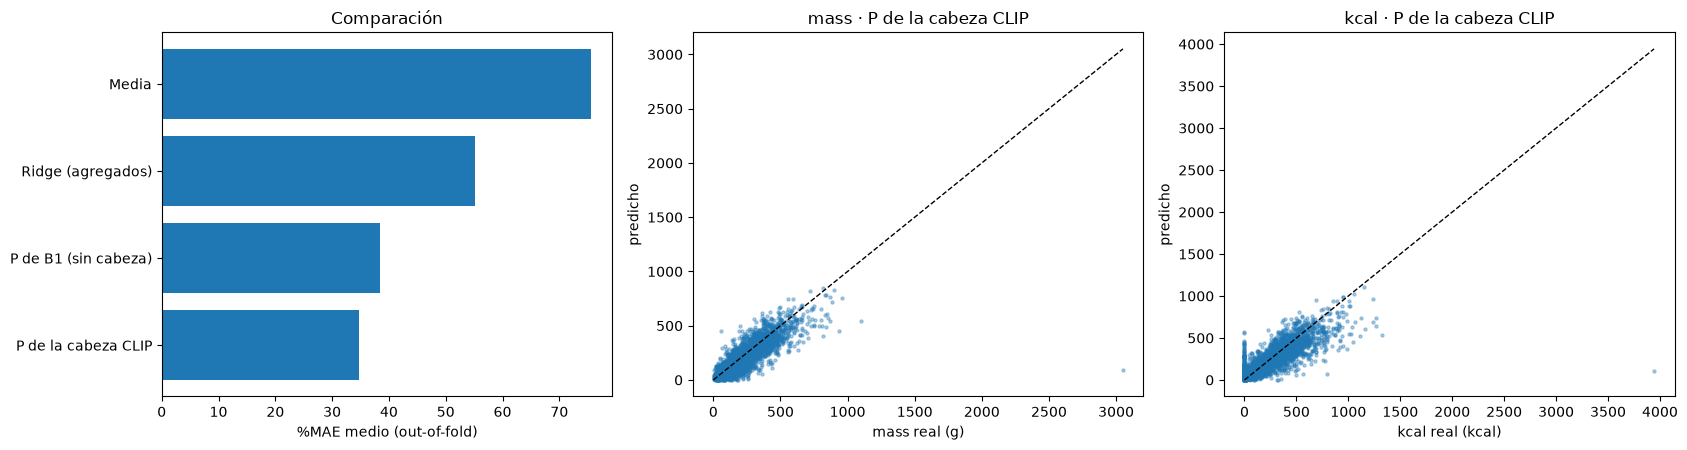

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
names = list(tab.index); means = tab["promedio"].values
ax[0].barh(names, means); ax[0].invert_yaxis(); ax[0].set_xlabel("%MAE medio (out-of-fold)"); ax[0].set_title("Comparación")
o = RESULTS[SRC_HEAD]["oof"]
for a, k in zip(ax[1:], [0, 1]):
    a.scatter(Y[:, k], o[:, k], s=5, alpha=0.35); lim = max(Y[:, k].max(), o[:, k].max()); a.plot([0, lim], [0, lim], "k--", lw=1)
    a.set_xlabel(f"{TARGETS[k]} real ({UNITS[k]})"); a.set_ylabel("predicho"); a.set_title(f"{TARGETS[k]} · {SRC_HEAD}")
plt.tight_layout(); plt.show()

### Cómo interpretar el resultado
- **El intervalo queda por encima de 0 en masa y/o calorías:** la mejor clasificación llega a la estimación final. Es el resultado que justifica haber integrado la cabeza.
- **El intervalo contiene 0:** la clase no es el cuello de botella de esta cabeza de nutrición. Las alturas, volúmenes y la profundidad predicha pesan más; mirar los mapas de altura de varios platos (sobre todo cuencos y sopas) es el siguiente paso.
- **Empeora:** lo más probable es un **cambio de dominio**. La cabeza se entrenó con fotos de FoodSeg103 (web, ángulos variados) y aquí ve bandejas cenitales de cafetería. Revisa en el diagnóstico de la sección 8 si la cabeza está prediciendo muchas veces `other ingredients` o `salad`, y prueba `P_MODE = "tau"` (cambia `P_MODE` arriba, vuelve a correr desde `compose_P` en adelante: `Q` ya está en caché).
- Recuerda que **lo que se aprende aquí** (`cls_emb`, `log_dens`) está indexado por las 103 clases de FoodSeg103, no por las de Nutrition5k.

## 11. Modelo final, tabla nutricional aprendida e inferencia

El modelo final usa la **`P` de la cabeza de clasificación**. Se entrena con los pliegues 1–4 (validación interna para el early stopping) y se deja el pliegue 0 como plato de demostración honesto. **Para producción conviene reentrenar con todos los platos.**

La tabla de densidades aprendida **cuadra por construcción** (las kcal salen de los macros). Se muestra para las 20 clases más frecuentes según la cabeza; es una buena forma de ver qué está aprendiendo la cabeza de nutrición sobre cada clase.

In [23]:
FINAL_SRC = SRC_HEAD
fc = FEATS[FINAL_SRC]
sp0 = fold_split(fold_all, inner_all, 0)
norm = fit_norm(fc, sp0["train"], True)
T0 = {s: to_tensors(fc, sp0[s], norm, True) for s in sp0}
final_model, _ = train_head(T0["train"], T0["val"], norm, C, CFG, VARIANT)
te = metrics(fc["Y"][sp0["test"]], predict_tensors(final_model, T0["test"]))
print(f"[{FINAL_SRC}] pliegue 0 (n={len(sp0['test'])}) %MAE:", np.round(te["pct"], 1), "| promedio", round(te["pct"].mean(), 1))
print(f"h0 (espesor mínimo aprendido) = {F.softplus(final_model.h0_raw).item():.2f} cm | kcal_gain = {final_model.kcal_gain.item():.3f}")

freq = fc["P"][sp0["train"]].astype(np.float32).sum((0, 1))
dens_tab = (torch.exp(final_model.log_dens) * final_model.prior).detach().cpu().numpy()
top = np.argsort(-freq)[:20]
kc = final_model.kcal_gain.item() * (9 * dens_tab[top, 1] + 4 * dens_tab[top, 2] + 4 * dens_tab[top, 3])
pd.DataFrame({"clase": [ID2NAME[i] for i in top], "peso_train": freq[top].round(0), "kcal/g": kc.round(2),
              "grasa g/g": dens_tab[top, 1].round(3), "carb g/g": dens_tab[top, 2].round(3), "prot g/g": dens_tab[top, 3].round(3)})

[P de la cabeza CLIP] pliegue 0 (n=750) %MAE: [25.4 26.8 40.  31.8 34.4] | promedio 31.7
h0 (espesor mínimo aprendido) = 0.56 cm | kcal_gain = 0.967


,clase,peso_train,kcal/g,grasa g/g,carb g/g,prot g/g
0,cilantro mint,1235.0,1.28,0.107,0.062,0.029
1,rice,794.0,1.31,0.059,0.113,0.091
2,cauliflower,600.0,0.39,0.010,0.054,0.024
3,shiitake,597.0,0.92,0.041,0.040,0.107
4,chicken duck,574.0,1.30,0.039,0.039,0.211
5,lettuce,558.0,0.80,0.050,0.057,0.036
6,carrot,545.0,0.52,0.012,0.084,0.024
7,broccoli,428.0,0.67,0.030,0.066,0.039
8,tomato,393.0,0.49,0.013,0.074,0.024
9,almond,372.0,2.66,0.219,0.101,0.093


### Inferencia sobre un plato

`predict_dish` recorre el pipeline completo con **una foto**, sin ningún archivo de profundidad:

```
rgb.png ─► B1 ─► regiones ──┬─► recortes ─► CLIP + cabeza ─► P ─┐
        └► DPT ─► profundidad ─► alturas y volumen (G, GL) ─────┴─► cabeza de nutrición ─► gramos, kcal, macros
```

La tabla muestra, por región, la clase de la cabeza, su probabilidad, **la clase que habría puesto B1** (para ver dónde difieren), el top-3 de la cabeza y lo que estima la cabeza de nutrición (gramos, kcal, grasa, carbohidratos, proteína). La región se numera igual en el panel central de la figura.

Recuerda que los gramos por región **no están validados individualmente**: solo se compara su suma con el total del plato.

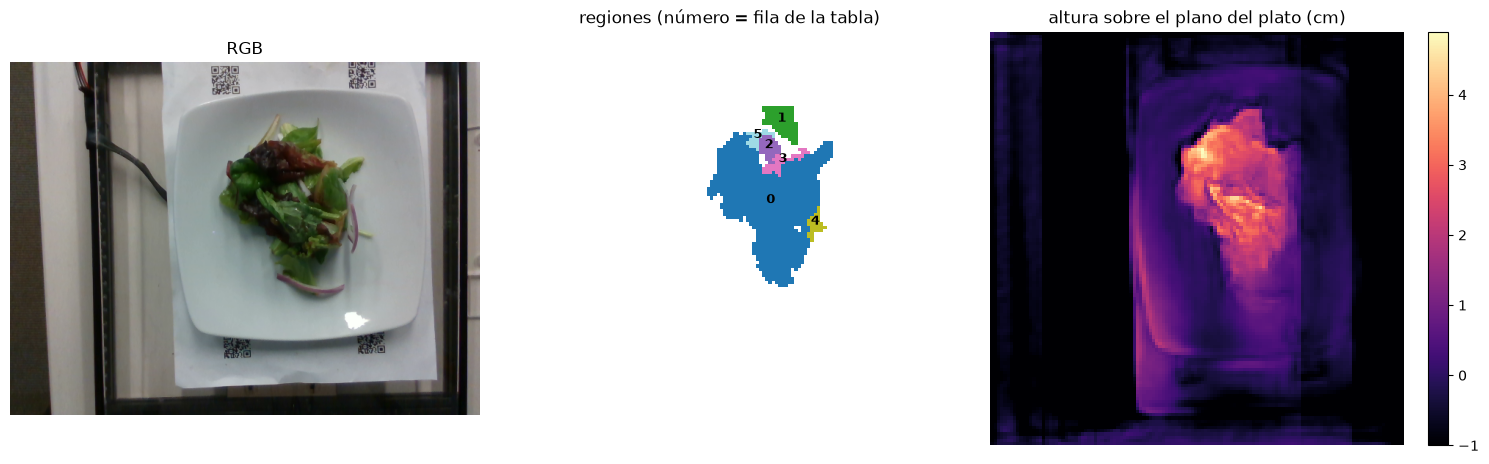

predicho: {'mass': 25.899999618530273, 'kcal': 27.299999237060547, 'fat': 1.600000023841858, 'carb': 1.7000000476837158, 'protein': 1.7999999523162842}
real    : {'mass': 23.0, 'kcal': 6.4, 'fat': 0.1, 'carb': 1.2, 'protein': 0.5}


,region,clase,prob_clase,clase_B1,top3,area_pct,altura_cm,gramos,kcal,grasa_g,carb_g,prot_g
0,0,lettuce,0.56,cilantro mint,"lettuce (0.56), cilantro mint (0.18), rape (0.15)",5.8,2.24,12.7,12.0,0.8,0.7,0.5
1,1,cilantro mint,0.75,cilantro mint,"cilantro mint (0.75), lettuce (0.17), spring o...",0.5,1.57,0.2,0.2,0.0,0.0,0.0
2,2,shiitake,0.46,pork,"shiitake (0.46), dried cranberries (0.07), blu...",0.3,2.48,7.6,8.1,0.4,0.6,0.7
3,3,cilantro mint,0.20,lettuce,"cilantro mint (0.20), lettuce (0.14), spring o...",0.2,2.32,0.7,0.8,0.0,0.1,0.0
4,4,onion,0.49,lettuce,"onion (0.49), spring onion (0.12), celery stic...",0.2,1.58,0.0,0.0,0.0,0.0,0.0
5,5,steak,0.22,steak,"steak (0.22), shiitake (0.11), pork (0.08)",0.2,2.91,4.6,6.3,0.4,0.3,0.5


In [24]:
@torch.no_grad()
def predict_dish(dish_dir, model, norm, seg, clip, depth_model, p_mode=None, tau=None, show=True):
    dish_dir = Path(dish_dir)
    rgb512 = load_rgb512(dish_dir)[None]
    ti, tv = to_topk(seg.probs(rgb512))
    depth = depth_from_model(depth_model, [dish_dir])[0]
    P_b1, G, M, GL, ex = build_regions(ti[0], tv[0].astype(np.float32), depth, seg.C, "local", return_extra=True)

    # 🆕 P con la cabeza de clasificación (recortes sobre la foto original)
    img = np.array(Image.open(dish_dir / "rgb.png").convert("RGB")); H, W = img.shape[:2]
    n = int(M.sum())
    Q = np.zeros((R_MAX, K_FOOD), np.float32)
    if n:
        mf = [up_nearest(m, H, W) for m in ex["masks"]]
        Q[:n] = clip.probs([crop_masked(img, m) for m in mf], [crop_bbox(img, m) for m in mf])
    P = compose_P(P_b1[None], Q[None], M[None], p_mode, tau)[0].astype(np.float32)

    a = make_inputs(P[None], G[None], M[None], GL[None], norm, True)
    t = {k: torch.from_numpy(v).to(DEVICE) for k, v in a.items()}
    model.eval(); out = fwd(model, t)
    grams, dens, total = out["grams"][0].cpu().numpy(), out["dens"][0].cpu().numpy(), out["total"][0].cpu().numpy()

    rows = []
    for r in range(n):
        p = P[r].copy(); p[BG_ID] = 0; c = int(p.argmax())
        pb = P_b1[r].copy(); pb[BG_ID] = 0; c_b1 = int(pb.argmax())
        top3 = np.argsort(-p)[:3]
        rows.append(dict(region=r, clase=ID2NAME[c], prob_clase=round(float(P[r][c]), 2), clase_B1=ID2NAME[c_b1],
                         top3=", ".join(f"{ID2NAME[j]} ({p[j]:.2f})" for j in top3),
                         area_pct=round(float(G[r, 0] * 100), 1), altura_cm=round(float(G[r, 1]), 2),
                         gramos=round(float(grams[r]), 1), kcal=round(float(grams[r] * dens[r, 0]), 1),
                         grasa_g=round(float(grams[r] * dens[r, 1]), 1), carb_g=round(float(grams[r] * dens[r, 2]), 1),
                         prot_g=round(float(grams[r] * dens[r, 3]), 1)))
    totals = {t_: float(round(v, 1)) for t_, v in zip(TARGETS, total)}
    if show:
        fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
        ax[0].imshow(img); ax[0].set_title("RGB"); ax[0].axis("off")
        lab = np.zeros((S, S), int)
        for r, m in enumerate(ex["masks"]): lab[m] = r + 1
        ax[1].imshow(np.ma.masked_equal(lab, 0), cmap="tab20", interpolation="nearest")
        for r, m in enumerate(ex["masks"]):
            yy, xx = np.nonzero(m); ax[1].text(xx.mean(), yy.mean(), str(r), ha="center", fontsize=9, weight="bold")
        ax[1].set_title("regiones (número = fila de la tabla)"); ax[1].axis("off")
        im = ax[2].imshow(np.clip(ex["height_cm"], -1, None), cmap="magma"); ax[2].axis("off")
        ax[2].set_title("altura sobre el plano del plato (cm)")
        plt.colorbar(im, ax=ax[2], fraction=0.046); plt.tight_layout(); plt.show()
    return pd.DataFrame(rows), totals

dish_demo = fc["ids"][sp0["test"][0]]
table, totals = predict_dish(img_root / dish_demo, final_model, norm, seg, clip, get_depth_model())
print("predicho:", totals); print("real    :", {t: float(round(v, 1)) for t, v in zip(TARGETS, df.set_index("dish_id").loc[dish_demo, TARGETS])})
table

### Guardar el modelo
El checkpoint guarda la cabeza de nutrición con su normalización y la configuración de `P` (fuente, modo y `TAU`). **No incluye** los pesos de CLIP ni de la cabeza de clasificación: se cargan aparte desde `CLIP_NAME` y `cabeza_clip_lineal.pt`.

In [25]:
ckpt = dict(state=final_model.state_dict(), norm=norm, cfg=CFG, variant=VARIANT, id2label=ID2NAME, n_classes=C,
            p_source="clip_head", p_mode=P_MODE, tau=TAU, clip_name=CLIP_NAME, clip_head_file=str(CLIP_HEAD_PT),
            geometry=dict(S=S, SEG_INPUT=SEG_INPUT, MIN_PX=MIN_PX, R_MAX=R_MAX, BG_ID=BG_ID, K_TOP=K_TOP, RING_IN=RING_IN,
                          RING_OUT=RING_OUT, K_FOOD=K_FOOD, CLIP_PAD=CLIP_PAD, depth_mode="model"), targets=TARGETS)
path = CACHE_DIR / "nutrition_head_v2_model_clip.pt"
torch.save(ckpt, path); print("guardado:", path)

def load_head(path):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = NutritionHead(ck["n_classes"], np.r_[ck["norm"]["prior"]], ck["norm"]["g_scale"], ck["norm"]["kcal_gain0"], ck["cfg"]["hidden"], ck["cfg"]["emb"],
                      ck["cfg"]["drop"], ck["variant"]["use_depth"], ck["variant"]["mass_mode"], ck["variant"]["kcal_mode"]).to(DEVICE)
    m.load_state_dict(ck["state"]); return m.eval(), ck["norm"], ck

guardado: head_cache_v2\nutrition_head_v2_model_clip.pt


## 12. Límites y siguientes pasos

**Lo que este notebook garantiza**
- La única entrada que cambia es `P`. `G`, `GL`, `M`, `A` y `V` salen de las mismas llamadas a `build_regions`, y el diagnóstico de la sección 8 lo comprueba.
- Las dos variantes se comparan con los mismos platos, pliegues y semilla, y con un intervalo de confianza por bootstrap pareado.

**Límites**
1. **Cambio de dominio de la cabeza.** Se entrenó con FoodSeg103 (fotos de la web). En Nutrition5k (bandejas cenitales) su acierto real **no está medido**: no hay etiquetas de clase por región. El diagnóstico muestra cuánto difiere de B1, no cuánto acierta.
2. **Las regiones siguen saliendo de B1.** La cabeza solo cambia la clase de regiones ya dibujadas: si B1 funde dos alimentos o parte uno en dos, eso se mantiene. En este notebook además dos regiones vecinas con la misma clase de la cabeza **no se fusionan** (las regiones se arman antes de clasificar).
3. **Regiones pequeñas.** El mínimo es 24 px en la rejilla de 128×128 (~0.15 % de la imagen). Un recorte tan pequeño se amplía a 224×224 para CLIP y llega borroso; `P_MODE = "tau"` es una forma de no fiarse de esos casos.
4. **Vocabulario.** Las 103 clases son las de FoodSeg103, no las de Nutrition5k, y la tabla de densidades se aprende solo de los totales del plato.
5. **Honestidad de la validación respecto a la cabeza.** La cabeza de clasificación nunca vio platos de Nutrition5k, así que no hay filtración por ese lado. B1 y el DPT sí pudieron verlos (nota 5 de la v2), por lo que la cifra de `model` puede ser algo optimista.
6. **Los gramos por región no están validados individualmente**, solo su suma contra el total del plato.

**Siguientes pasos**
- Fine-tuning de B1 y ampliación del vocabulario con el autoetiquetado de Nutrition5k. Al regenerar `raw_seg.npz` hay que borrar también `clip_feats_model_local.npz`.
- Una evaluación a mano de `P` en unas decenas de platos de Nutrition5k (clase correcta por región) para medir el acierto real de la cabeza en este dominio.
- Para producción: reentrenar con todos los platos y sustituir la tabla de densidades aprendida por una tabla nutricional real, usando solo los **gramos** de la cabeza.